In [1]:
# function 파일 오류 수정 후 런타임을 재시작하지 않고 수정내용을 반영하는 방법
# import importlib
# import multiclass_functions
# importlib.reload(multiclass_functions)

from multiclass_functions import *

In [2]:
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms, datasets
import matplotlib.pyplot as plt
import numpy as np
import os
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [14]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 5
criterion = nn.CrossEntropyLoss()
new_model_train = True

model_type = 'CNN_deep'
dataset = 'CIFAR10'

save_dir = 'results'
os.makedirs(save_dir, exist_ok=True)

save_model_path = f'{save_dir}/{model_type}_{dataset}.pt'

In [15]:
transform = transforms.ToTensor()
train_DS = datasets.CIFAR10(root='data', train=True, transform=transform, download=True)
test_DS = datasets.CIFAR10(root='data', train=False, transform=transform, download=True)

train_DL = DataLoader(train_DS, batch_size= BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=True)

In [16]:
x_batch, y_batch = next(iter(train_DL))
print(x_batch.shape)

torch.Size([32, 3, 32, 32])


In [20]:
class CNN(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.conv1 = nn.Sequential(
            nn.Conv2d(3,8,3, padding=1),    # input(32,3,32,32)
            nn.BatchNorm2d(8),
            nn.ReLU()
            )
        self.maxpool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Sequential(
            nn.Conv2d(8,16,3),
            nn.BatchNorm2d(16),
            nn.ReLU()
            )
        self.maxpool2 = nn.MaxPool2d(2)
        self.conv3 = nn.Sequential(
            nn.Conv2d(16,32,3),
            nn.BatchNorm2d(32),
            nn.ReLU()
            )
        self.maxpool3 = nn.MaxPool2d(2)
        self.fc = nn.Linear(32*2*2, 10)

    def forward(self, x, *args, **kwargs):
        x = self.conv1(x)
        x = self.maxpool1(x)
        x = self.conv2(x)
        x = self.maxpool2(x)
        x = self.conv3(x)
        x = self.maxpool3(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x


class CNN_deep(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args,**kwargs)
        self.conv_block1 = nn.Sequential(nn.Conv2d(3,32,3, padding=1),
                                         nn.BatchNorm2d(32),
                                         nn.ReLU(),
                                         nn.Conv2d(32,32,3, padding=1),
                                         nn.BatchNorm2d(32),
                                         nn.ReLU())
        self.maxpool1 = nn.MaxPool2d(2)

        self.conv_block2 = nn.Sequential(nn.Conv2d(32,64,3, padding=1),
                                         nn.BatchNorm2d(64),
                                         nn.ReLU(),
                                         nn.Conv2d(64,64,3, padding=1),
                                         nn.BatchNorm2d(64),
                                         nn.ReLU(),
                                         nn.Conv2d(64,64,3, padding=1),
                                         nn.BatchNorm2d(64),
                                         nn.ReLU())

        self.maxpool2 = nn.MaxPool2d(2)
        
        self.conv_block3 = nn.Sequential(nn.Conv2d(64,128,3, padding=1),
                                         nn.BatchNorm2d(128),
                                         nn.ReLU(),
                                         nn.Conv2d(128,128,3, padding=1),
                                         nn.BatchNorm2d(128),
                                         nn.ReLU(),
                                         nn.Conv2d(128,128,3, padding=1),
                                         nn.BatchNorm2d(128),
                                         nn.ReLU())

        self.maxpool3 = nn.MaxPool2d(2)

        self.fc = nn.Sequential(nn.Linear(128*4*4,512),
                                nn.ReLU(),
                                nn.Linear(512, 10))

    def forward(self, x, *args, **kwargs):
        x = self.conv_block1(x)
        x = self.maxpool1(x)
        x = self.conv_block2(x)
        x = self.maxpool2(x)
        x = self.conv_block3(x)
        x = self.maxpool3(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

In [21]:
model = globals()[model_type]().to(device)

model.eval()
with torch.no_grad():
    print(model(x_batch.to(device)).shape)

torch.Size([32, 10])


Epoch : 1, train loss : 1.329
--------------------
Epoch : 2, train loss : 0.876
--------------------
Epoch : 3, train loss : 0.703
--------------------
Epoch : 4, train loss : 0.586
--------------------
Epoch : 5, train loss : 0.499
--------------------


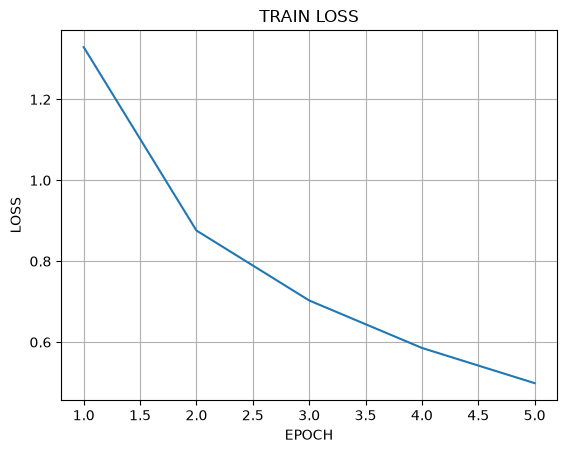

In [22]:
if new_model_train:
    optimizer = optim.Adam(model.parameters(), lr=LR)
    loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

    torch.save(model, save_model_path)

    plt.figure()
    plt.plot(range(1, EPOCH+1), loss_history)
    plt.xlabel('EPOCH')
    plt.ylabel('LOSS')
    plt.title('TRAIN LOSS')
    plt.grid()

In [23]:
load_model = torch.load(save_model_path, map_location= device, weights_only=False)

In [24]:
Test(load_model, test_DL)
print(count_params(load_model))

Test accuracy : 7643 / 10000 (76.4 %)
1527018


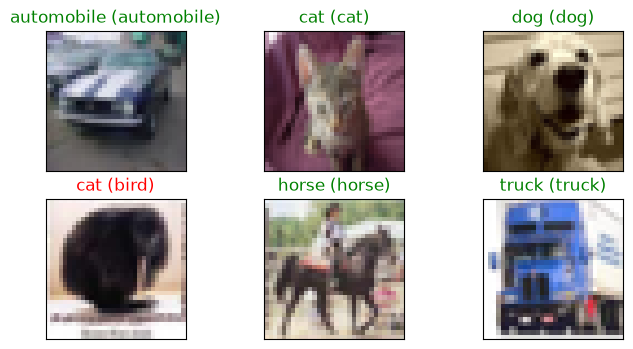

In [25]:
Test_plot(load_model, test_DL)

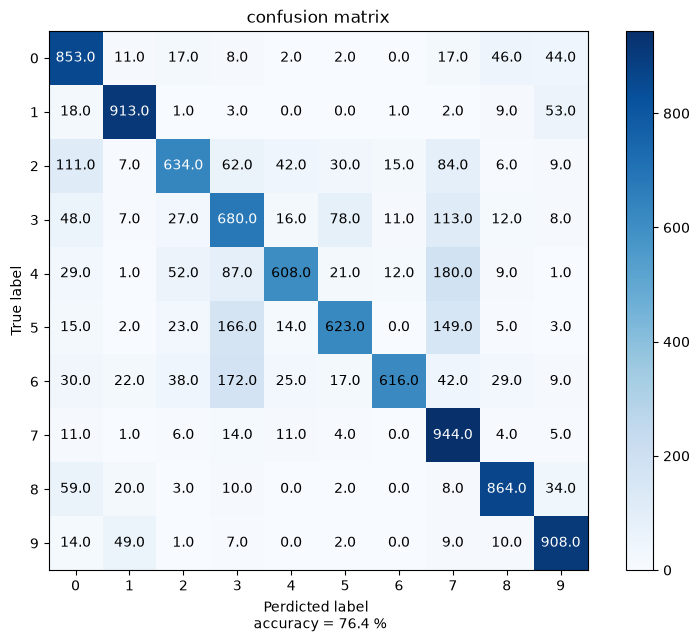

In [26]:
confusion = get_conf(load_model, test_DL)

plot_confusion_matrix(confusion)

torch.Size([32, 32, 32, 32])
torch.Size([32, 64, 16, 16])
torch.Size([32, 128, 8, 8])


Text(0.5, 1.0, 'bird (bird)')

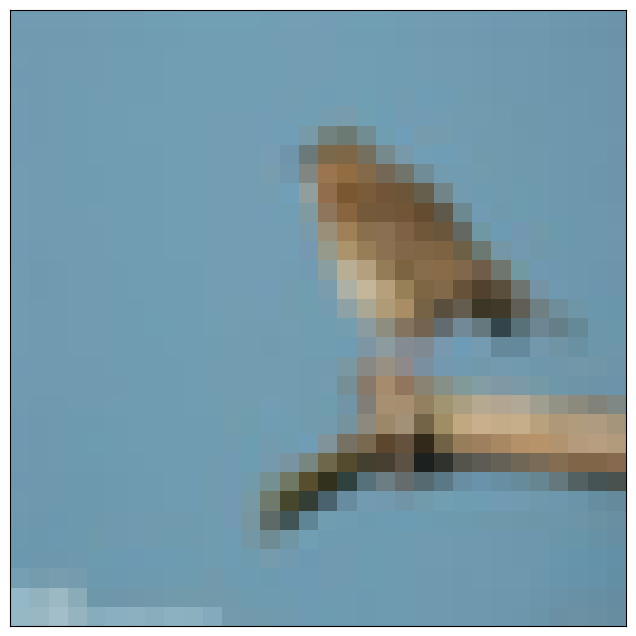

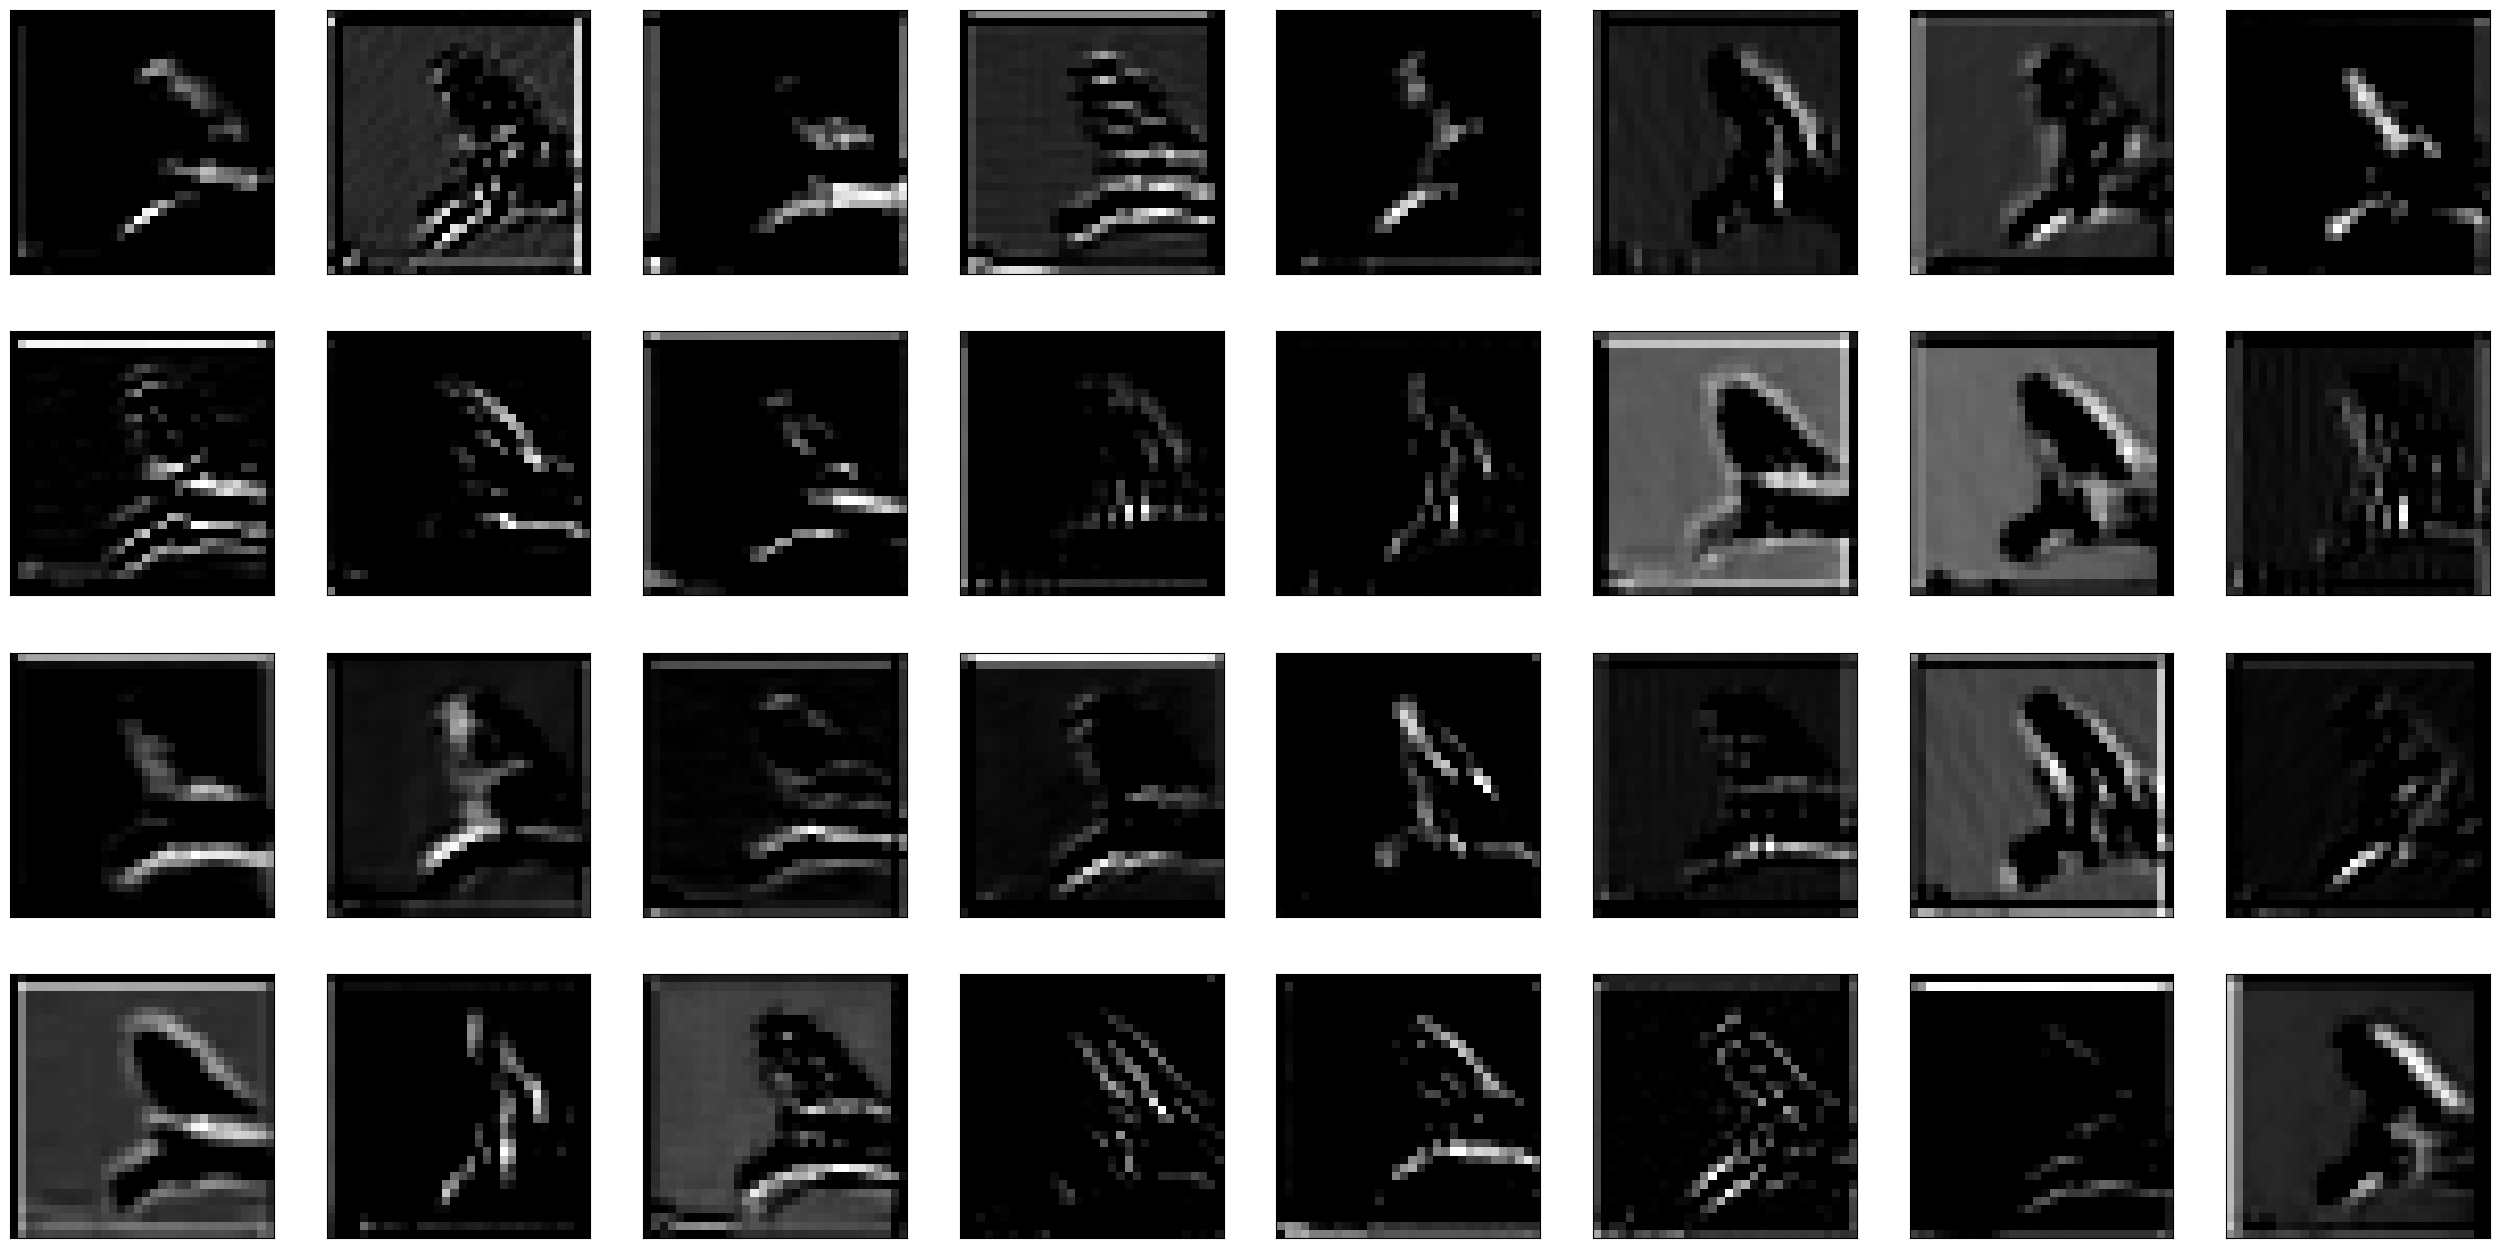

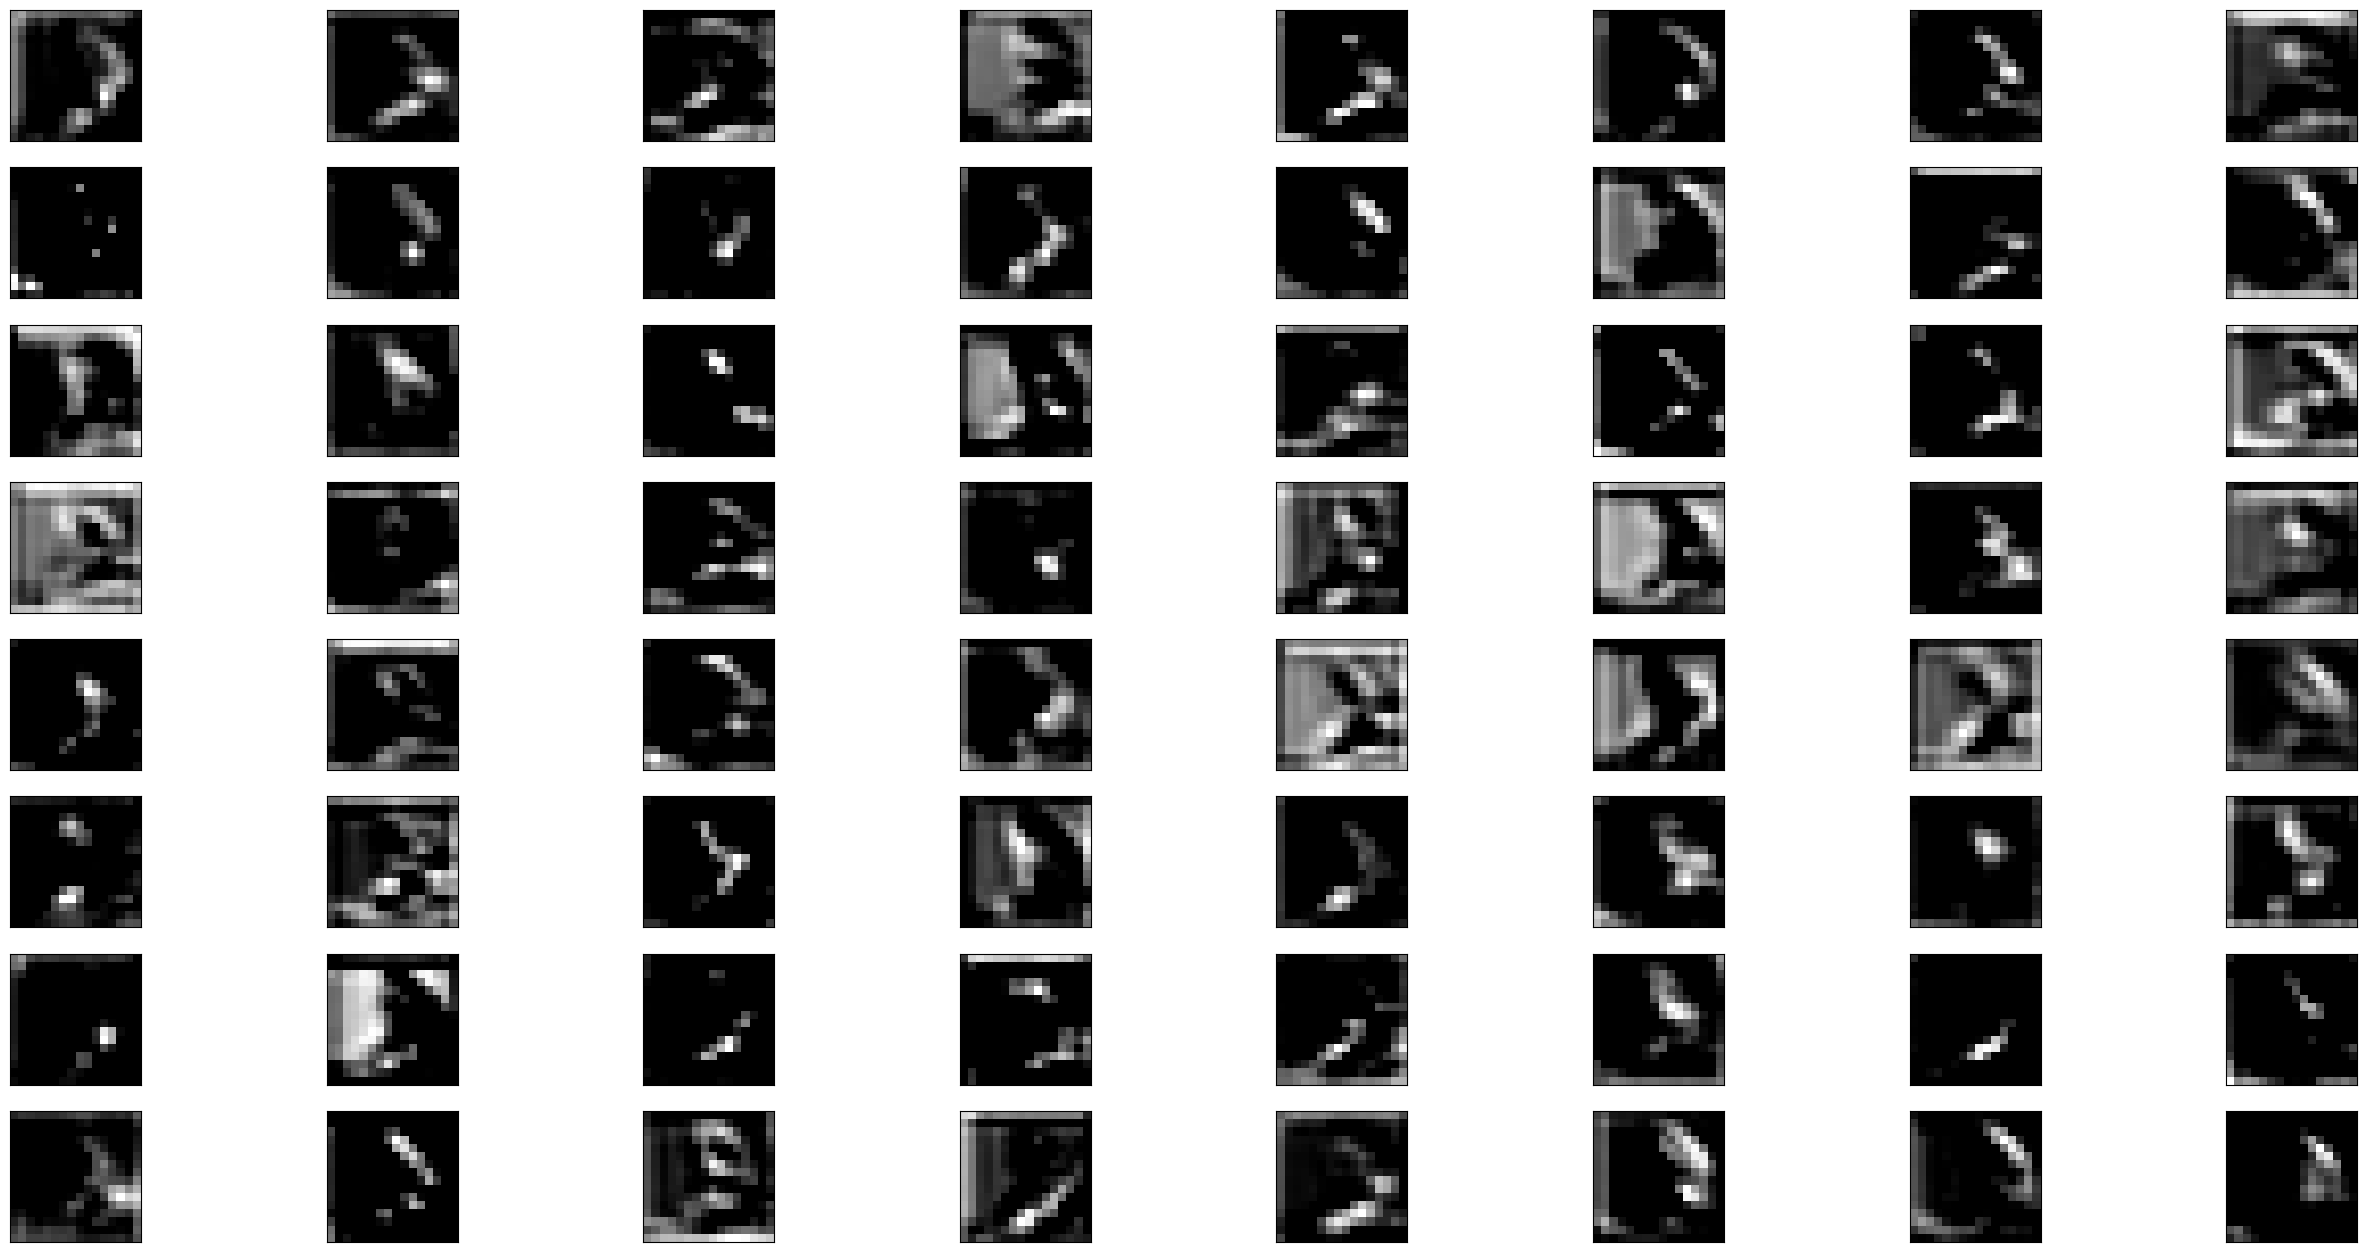

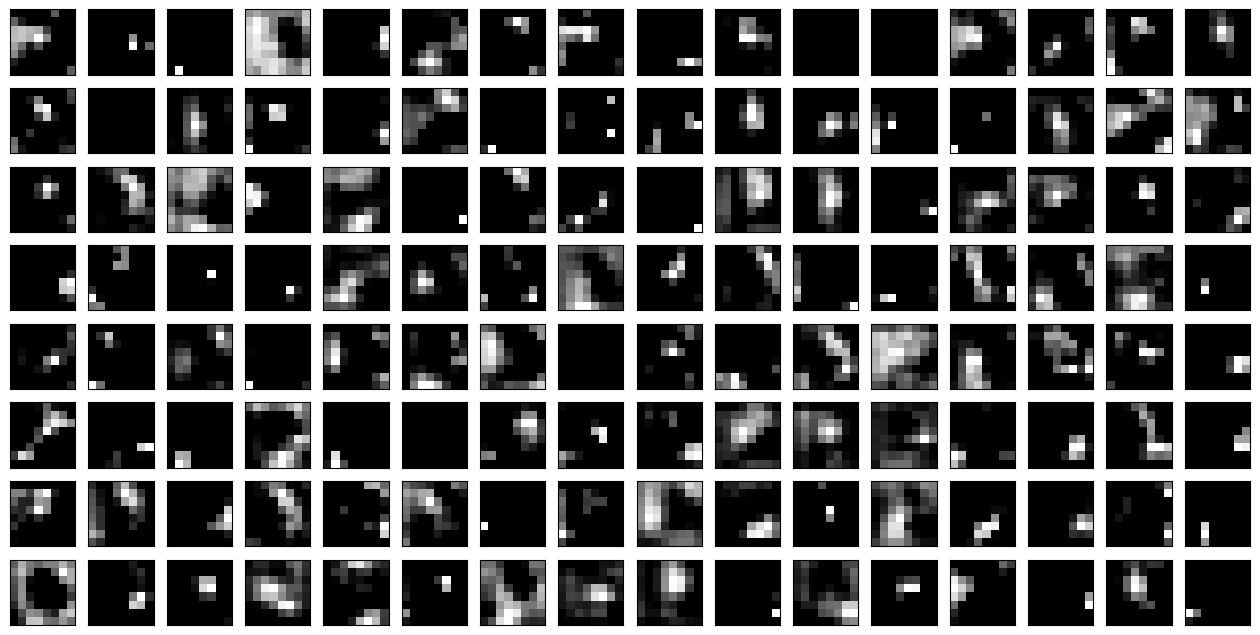

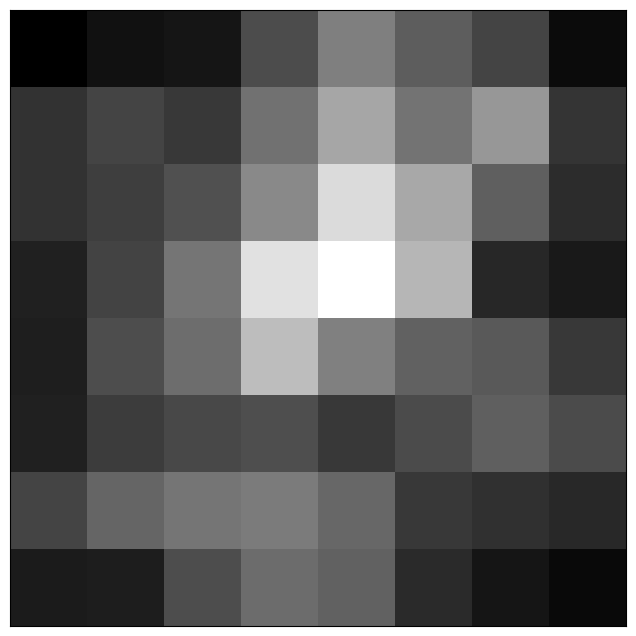

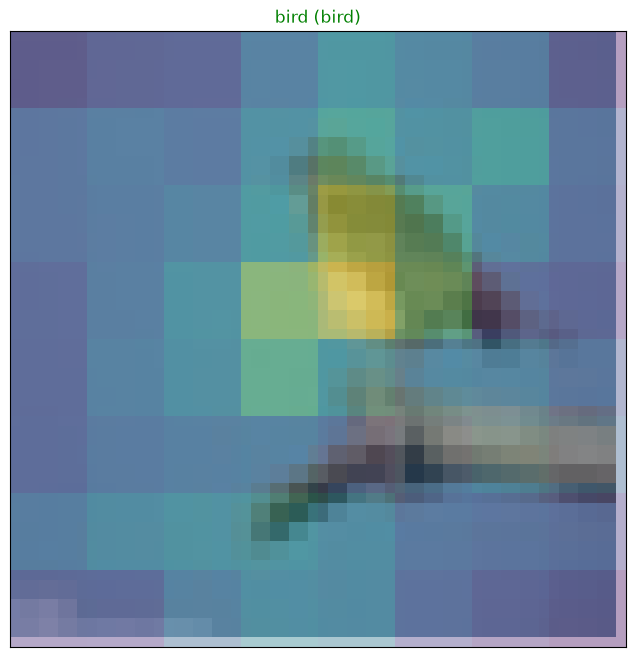

In [ ]:
load_model.eval()
with torch.no_grad():
    x_batch, y_batch = next(iter(test_DL))
    x_batch = x_batch.to(DEVICE)
    y_batch = y_batch.to(DEVICE)
    y_hat = load_model(x_batch)
    pred = y_hat.argmax(dim=1)

    if model_type == 'CNN':
        feature_map1 = load_model.conv1(x_batch)
        feature_map2 = load_model.conv2(load_model.maxpool1(feature_map1))
        feature_map3 = load_model.conv3(load_model.maxpool2(feature_map2))
    else:
        feature_map1 = load_model.conv_block1(x_batch)
        feature_map2 = load_model.conv_block2(load_model.maxpool1(feature_map1))
        feature_map3 = load_model.conv_block3(load_model.maxpool2(feature_map2))

x_batch = x_batch.cpu()
feature_map1 = feature_map1.cpu()
feature_map2 = feature_map2.cpu()
feature_map3 = feature_map3.cpu()

plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(x_batch[0].permute(1,2,0))

print(feature_map1.shape)
plt.figure(figsize=(32,16))
for idx in range(feature_map1.shape[1]):
    plt.subplot(4,8, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map1[0,idx], cmap='gray')

print(feature_map2.shape)
plt.figure(figsize=(32,16))
for idx in range(feature_map2.shape[1]):
    plt.subplot(8,8, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map2[0,idx], cmap='gray')

print(feature_map3.shape)
plt.figure(figsize=(16,8))
for idx in range(feature_map3.shape[1]):
    plt.subplot(8,16, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map3[0,idx], cmap='gray')

summed_map = feature_map3.sum(dim=1)
plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(summed_map[0], cmap='gray')

plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(x_batch[0].permute(1,2,0))
plt.imshow(summed_map[0], extent=[0,32,32,0], alpha=0.4, cmap='viridis')
pred_item = test_DS.classes[pred[0].item()]
true_item = test_DS.classes[y_batch[0].item()]
plt.title(f'{pred_item} ({true_item})', color='g' if pred_item == true_item else 'r')
     